# Buscador de jugadores similares por embeddings (FBref La Liga 2016-2026)

Dos modos de búsqueda:
- **Temporada**: el más parecido a un jugador en un año concreto (Pedri 2026 → …).
- **Carrera**: perfil promedio de un jugador vs otros (Pedri en general → Iniesta…),
  permite comparar gente que no coincidió en el tiempo.

Porteros van en un espacio aparte (sus métricas no son comparables con jugadores de campo).

Pipeline: merge de tablas → por-90 → filtro de minutos → estandarización →
similitud coseno → funciones de búsqueda + mapa 2D.

In [66]:
%pip install -q pandas numpy scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [67]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("data/raw/fbref_r")

def load(name):
    return pd.read_csv(DATA_DIR / f"{name}.csv")

KEYS = ["Season_End_Year", "Squad", "Comp", "Player"]  # claves de merge

## 1. Cargar y mergear las tablas de jugador de campo
Se hace merge por jugador-temporada-equipo. Al elegir columnas evitamos duplicados
(`Int`, `Ast`, etc. aparecen en varias tablas → nos quedamos con una fuente).

In [68]:
standard   = load("laliga_player_standard")
shooting   = load("laliga_player_shooting")
passing    = load("laliga_player_passing")
possession = load("laliga_player_possession")
defense    = load("laliga_player_defense")
misc       = load("laliga_player_misc")

# De cada tabla nos quedamos con KEYS + columnas utiles (evita colisiones)
base = standard[KEYS + ["Pos", "Nation", "Age", "Min_Playing", "Mins_Per_90_Playing",
    "Gls", "Ast", "PrgC_Progression", "PrgP_Progression", "PrgR_Progression",
    "xG_Per", "npxG_Per", "xAG_Per", "npxG+xAG_Per", "Url"]].copy()

sh = shooting[KEYS + ["Sh_per_90_Standard", "SoT_per_90_Standard", "G_per_Sh_Standard",
    "Dist_Standard", "npxG_per_Sh_Expected"]]

pa = passing[KEYS + ["Cmp_percent_Total", "KP", "PPA", "Final_Third", "xA", "Mins_Per_90"]]

po = possession[KEYS + ["Touches_Touches", "Att 3rd_Touches", "Att_Take", "Succ_percent_Take",
    "PrgC_Carries", "PrgDist_Carries", "CPA_Carries", "Rec_Receiving", "PrgR_Receiving"]]

de = defense[KEYS + ["Tkl_Tackles", "Int", "Blocks_Blocks", "Clr"]]

mi = misc[KEYS + ["Recov", "Won_percent_Aerial", "Fld"]]

df = (base.merge(sh, on=KEYS, how="left")
           .merge(pa, on=KEYS, how="left")
           .merge(po, on=KEYS, how="left")
           .merge(de, on=KEYS, how="left")
           .merge(mi, on=KEYS, how="left"))

print("tabla mergeada:", df.shape)
df.head(3)

tabla mergeada: (9507, 46)


,Season_End_Year,Squad,Comp,Player,Pos,Nation,Age,Min_Playing,Mins_Per_90_Playing,Gls,...,CPA_Carries,Rec_Receiving,PrgR_Receiving,Tkl_Tackles,Int,Blocks_Blocks,Clr,Recov,Won_percent_Aerial,Fld
0,2010,Almería,La Liga,Santiago Acasiete,DF,PER,31,2735,30.4,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2010,Almería,La Liga,Diego Alves,GK,BRA,24,3302,36.7,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2010,Almería,La Liga,Miguel Ángel Nieto,MF,ESP,23,418,4.6,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Convertir acumulados a por-90
Las columnas de volumen (KP, Touches, Tkl, Carries...) se dividen entre `Mins_Per_90`
para obtener el rate. Las que ya son `_Per`/`_per_90`/`_percent` se dejan tal cual.

In [69]:
# minutos jugados en 90s (para convertir a per-90). Usamos el de standard.
p90 = df["Mins_Per_90_Playing"].replace(0, np.nan)

# columnas que son acumulados y hay que pasar a per-90
to_per90 = ["KP", "PPA", "Final_Third", "xA", "Touches_Touches", "Att 3rd_Touches",
    "Att_Take", "PrgC_Carries", "PrgDist_Carries", "CPA_Carries", "Rec_Receiving",
    "PrgR_Receiving", "Tkl_Tackles", "Int", "Blocks_Blocks", "Clr", "Recov", "Fld",
    "PrgC_Progression", "PrgP_Progression", "PrgR_Progression"]

for c in to_per90:
    df[c + "_p90"] = pd.to_numeric(df[c], errors="coerce") / p90

# columnas que ya son rate/percent/per-90 y usamos directamente
already_rate = ["xG_Per", "npxG_Per", "xAG_Per", "npxG+xAG_Per",
    "Sh_per_90_Standard", "SoT_per_90_Standard", "G_per_Sh_Standard", "Dist_Standard",
    "npxG_per_Sh_Expected", "Cmp_percent_Total", "Succ_percent_Take", "Won_percent_Aerial"]

FEATURES = already_rate + [c + "_p90" for c in to_per90]
print(f"{len(FEATURES)} features de estilo:")
print(FEATURES)

33 features de estilo:
['xG_Per', 'npxG_Per', 'xAG_Per', 'npxG+xAG_Per', 'Sh_per_90_Standard', 'SoT_per_90_Standard', 'G_per_Sh_Standard', 'Dist_Standard', 'npxG_per_Sh_Expected', 'Cmp_percent_Total', 'Succ_percent_Take', 'Won_percent_Aerial', 'KP_p90', 'PPA_p90', 'Final_Third_p90', 'xA_p90', 'Touches_Touches_p90', 'Att 3rd_Touches_p90', 'Att_Take_p90', 'PrgC_Carries_p90', 'PrgDist_Carries_p90', 'CPA_Carries_p90', 'Rec_Receiving_p90', 'PrgR_Receiving_p90', 'Tkl_Tackles_p90', 'Int_p90', 'Blocks_Blocks_p90', 'Clr_p90', 'Recov_p90', 'Fld_p90', 'PrgC_Progression_p90', 'PrgP_Progression_p90', 'PrgR_Progression_p90']


In [70]:
# Nombres legibles solo para mostrar (los DataFrames mantienen los originales)
NOMBRES = {
    # Finalización
    "xG_Per": "xG /90",
    "npxG_Per": "xG sin penaltis /90",
    "xAG_Per": "Asist. esperadas /90",
    "npxG+xAG_Per": "xG+xAG /90",
    "Sh_per_90_Standard": "Tiros /90",
    "SoT_per_90_Standard": "Tiros a puerta /90",
    "G_per_Sh_Standard": "Goles por tiro",
    "Dist_Standard": "Dist. media de tiro",
    "npxG_per_Sh_Expected": "Calidad de tiro (npxG/tiro)",
    # Creación / pase
    "Cmp_percent_Total": "% acierto de pase",
    "KP_p90": "Pases clave /90",
    "PPA_p90": "Pases al área /90",
    "Final_Third_p90": "Pases al último tercio /90",
    "xA_p90": "Asist. esperadas (xA) /90",
    # Progresión
    "PrgP_Progression_p90": "Pases progresivos /90",
    "PrgC_Carries_p90": "Conducciones progresivas /90",
    "PrgDist_Carries_p90": "Dist. progresando /90",
    "PrgR_Receiving_p90": "Recepciones progresivas /90",
    "CPA_Carries_p90": "Conducciones al área /90",
    "PrgC_Progression_p90": "Conducciones progresivas /90",
    "PrgP_Progression_p90": "Pases progresivos /90",
    "PrgR_Progression_p90": "Recepciones progresivas /90",
    # Posesión / regate
    "Touches_Touches_p90": "Toques /90",
    "Att 3rd_Touches_p90": "Toques en campo rival /90",
    "Att_Take_p90": "Regates intentados /90",
    "Succ_percent_Take": "% regates exitosos",
    "Rec_Receiving_p90": "Balones recibidos /90",
    # Defensa
    "Tkl_Tackles_p90": "Entradas /90",
    "Int_p90": "Intercepciones /90",
    "Blocks_Blocks_p90": "Bloqueos /90",
    "Clr_p90": "Despejes /90",
    "Recov_p90": "Recuperaciones /90",
    "Won_percent_Aerial": "% duelos aéreos ganados",
    "Fld_p90": "Faltas recibidas /90",
}

def bonito(col):
    """Nombre legible de una feature; si no está en el diccionario, limpia guiones."""
    return NOMBRES.get(col, col.replace("_", " "))

## 3. Filtrar minutos y separar porteros
- Porteros (`Pos` contiene 'GK') a un lado.
- Jugadores de campo con ≥ MIN_MINUTOS en la temporada, para que los rate no sean ruido.

In [71]:
MIN_MINUTOS = 300   # ~10 partidos completos

df["is_gk"] = df["Pos"].astype(str).str.contains("GK")

field = df[(~df["is_gk"]) & (df["Min_Playing"] >= MIN_MINUTOS)].copy()

# Rellenar NaN de features con 0 (ausencia de esa accion) y limpiar infinitos
field[FEATURES] = field[FEATURES].replace([np.inf, -np.inf], np.nan).fillna(0)

print(f"jugadores de campo (jugador-temporada) con >= {MIN_MINUTOS} min: {len(field)}")
print(f"jugadores unicos: {field['Player'].nunique()}")

jugadores de campo (jugador-temporada) con >= 300 min: 6699
jugadores unicos: 2082


## 4. Estandarizar y construir la matriz jugador-temporada
`StandardScaler` es imprescindible: xG_Per (~0.3) y Touches_p90 (~60) están en escalas
incomparables. Tras esto, cada feature tiene media 0 y desviación 1.

In [72]:
# etiqueta legible por fila
field["label"] = field["Player"] + " (" + field["Season_End_Year"].astype(str) + ", " + field["Squad"] + ")"
field = field.reset_index(drop=True)

scaler = StandardScaler()
X = scaler.fit_transform(field[FEATURES])

# matriz de similitud coseno jugador-temporada x jugador-temporada
S_season = cosine_similarity(X)
print("matriz de similitud temporada:", S_season.shape)

# Agrupa las posiciones de FBref en familias compatibles para el filtro.
# FBref usa: GK, DF, MF, FW (y combinaciones como "MF,FW", "DF,MF").
def grupo_pos(pos):
    pos = str(pos)
    tokens = pos.replace(" ", "").split(",")
    # familia por el primer token (posición principal)
    main = tokens[0]
    return main  # "DF", "MF", "FW"...

field["pos_group"] = field["Pos"].map(grupo_pos)

# Qué grupos se consideran "compatibles" entre sí al buscar similares
COMPATIBLES = {
    "GK": {"GK"},
    "DF": {"DF", "MF"},        # laterales/carrileros rozan el MF
    "MF": {"MF", "FW", "DF"},  # mediocentros: sobre todo MF, algo de FW/DF
    "FW": {"FW", "MF"},
}
print(field["pos_group"].value_counts())

matriz de similitud temporada: (6699, 6699)
pos_group
DF    2737
MF    2257
FW    1705
Name: count, dtype: int64


## 5. Modo TEMPORADA: similares a un jugador en un año concreto

In [73]:
def similares_temporada(nombre, anyo, n=10, misma_pos=True):
    """Similares a <nombre> en <anyo>. Si misma_pos, solo compara posiciones compatibles."""
    mask = (field["Player"].str.contains(nombre, case=False, na=False)) & (field["Season_End_Year"] == anyo)
    if not mask.any():
        print(f"No encuentro a '{nombre}' en {anyo}. Revisa nombre/temporada.")
        return None
    idx = field[mask].index[0]
    sims = S_season[idx]

    orden = np.argsort(sims)[::-1]
    orden = [i for i in orden if i != idx]

    if misma_pos:
        compat = COMPATIBLES.get(field.loc[idx, "pos_group"], {field.loc[idx, "pos_group"]})
        orden = [i for i in orden if field.loc[i, "pos_group"] in compat]

    orden = orden[:n]
    out = field.loc[orden, ["Player", "Season_End_Year", "Squad", "Pos"]].copy()
    out["similitud"] = sims[orden].round(3)
    print(f"Más parecidos a {field.loc[idx,'label']} (pos: {field.loc[idx,'pos_group']}):\n")
    return out.reset_index(drop=True)

similares_temporada("Borja Iglesias", 2025, n=10)

Más parecidos a Borja Iglesias (2025, Celta Vigo) (pos: FW):



,Player,Season_End_Year,Squad,Pos,similitud
0,Cyle Larin,2025,Mallorca,FW,0.939
1,Ferrán Torres,2025,Barcelona,"FW,MF",0.938
2,Robert Lewandowski,2025,Barcelona,FW,0.936
3,Ayoze Pérez,2025,Villarreal,FW,0.936
4,Artem Dovbyk,2024,Girona,FW,0.925
5,Hugo Duro,2025,Valencia,FW,0.924
6,Thierno Barry,2025,Villarreal,FW,0.921
7,Gorka Guruzeta,2025,Athletic Club,FW,0.921
8,Alexander Sørloth,2025,Atlético Madrid,FW,0.918
9,Raúl,2025,Osasuna,"FW,MF",0.916


## 6. Modo CARRERA: perfil promedio por jugador
Promediamos las features estandarizadas de todas las temporadas de cada jugador.
Así comparamos perfiles de época distinta (Pedri vs Iniesta aunque no coincidieran).

In [74]:
# DataFrame estandarizado con nombre + posición dominante del jugador
Xdf = pd.DataFrame(X, columns=FEATURES)
Xdf["Player"] = field["Player"].values

career = Xdf.groupby("Player").mean()
career_labels = career.index.to_numpy()
S_career = cosine_similarity(career.values)

# posición más frecuente de cada jugador en su carrera
pos_por_jugador = field.groupby("Player")["pos_group"].agg(lambda s: s.value_counts().index[0])
career_pos = pos_por_jugador.reindex(career_labels).to_numpy()

print("jugadores en modo carrera:", career.shape[0])

def similares_carrera(nombre, n=10, misma_pos=True):
    matches = [p for p in career_labels if nombre.lower() in p.lower()]
    if not matches:
        print(f"No encuentro a '{nombre}'.")
        return None
    player = matches[0]
    idx = list(career_labels).index(player)
    sims = S_career[idx]

    orden = np.argsort(sims)[::-1]
    orden = [i for i in orden if i != idx]

    if misma_pos:
        compat = COMPATIBLES.get(career_pos[idx], {career_pos[idx]})
        orden = [i for i in orden if career_pos[i] in compat]

    orden = orden[:n]
    out = pd.DataFrame({
        "Player": career_labels[orden],
        "pos": career_pos[orden],
        "similitud": sims[orden].round(3),
    })
    print(f"Perfil de carrera más parecido a {player} (pos: {career_pos[idx]}):\n")
    return out

similares_carrera("Pedri", n=10)

jugadores en modo carrera: 2082
Perfil de carrera más parecido a Pedri (pos: MF):



,Player,pos,similitud
0,Pablo Fornals,MF,0.924
1,Frenkie de Jong,MF,0.910
2,Domingos André Ribeiro Almeida,MF,0.910
3,Luka Modrić,MF,0.901
4,Rodrigo De Paul,MF,0.900
5,Pablo Torre,MF,0.897
6,Giovani Lo Celso,MF,0.894
7,Moi Gómez,MF,0.891
8,David Silva,MF,0.879
9,Federico Valverde,MF,0.870


## 7. Mapa 2D de jugadores (PCA)
Proyección de todos los jugador-temporada a 2D, coloreada por posición.
Útil para ver los clusters (delanteros, centrales, laterales, creadores...).

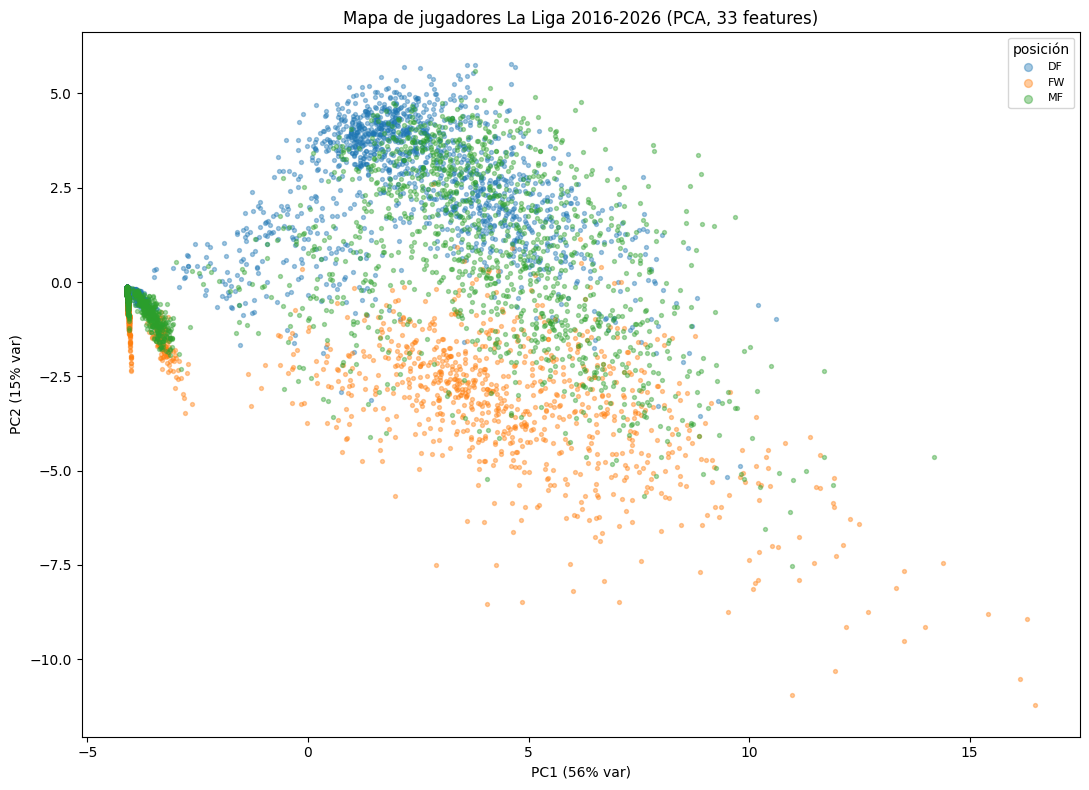

In [75]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=0)
coords = pca.fit_transform(X)

# posicion principal (primer token de Pos)
field["pos_main"] = field["Pos"].astype(str).str.split(",").str[0]

fig, ax = plt.subplots(figsize=(11, 8))
for pos, g in field.groupby("pos_main"):
    sel = g.index
    ax.scatter(coords[sel, 0], coords[sel, 1], s=8, alpha=0.4, label=pos)
ax.legend(title="posición", markerscale=2, fontsize=8)
ax.set_title(f"Mapa de jugadores La Liga 2016-2026 (PCA, {len(FEATURES)} features)")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.0f}% var)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.0f}% var)")
plt.tight_layout()
plt.show()

## 8. Comparar dos jugadores lado a lado (radar de percentiles)
Para entender POR QUÉ dos jugadores son similares: sus features en percentiles.

In [78]:
def comparar(nombre_a, anyo_a, nombre_b, anyo_b, top=12):
    def fila(nombre, anyo):
        m = (field["Player"].str.contains(nombre, case=False, na=False)) & (field["Season_End_Year"] == anyo)
        return field[m].index[0] if m.any() else None
    ia, ib = fila(nombre_a, anyo_a), fila(nombre_b, anyo_b)
    if ia is None or ib is None:
        print("No encuentro a uno de los dos."); return None
    # percentiles sobre la poblacion de campo
    pct = field[FEATURES].rank(pct=True)
    comp = pd.DataFrame({
        field.loc[ia,"label"]: (pct.loc[ia]*100).round(0),
        field.loc[ib,"label"]: (pct.loc[ib]*100).round(0),
    })
    comp["dif"] = (comp.iloc[:,0] - comp.iloc[:,1]).abs()
    comp.index = [bonito(i) for i in comp.index]
    return comp.sort_values("dif").head(top)   # features donde MAS se parecen

comparar("Borja Iglesias", 2025, "Ferrán Torres", 2025)

,"Borja Iglesias (2025, Celta Vigo)","Ferrán Torres (2025, Barcelona)",dif
Asist. esperadas (xA) /90,33.0,33.0,0.0
Recuperaciones /90,52.0,52.0,0.0
Toques /90,52.0,53.0,1.0
Goles por tiro,96.0,95.0,1.0
Dist. progresando /90,51.0,52.0,1.0
Entradas /90,52.0,53.0,1.0
Bloqueos /90,52.0,53.0,1.0
xG+xAG /90,98.0,100.0,2.0
Calidad de tiro (npxG/tiro),98.0,96.0,2.0
Balones recibidos /90,52.0,54.0,2.0


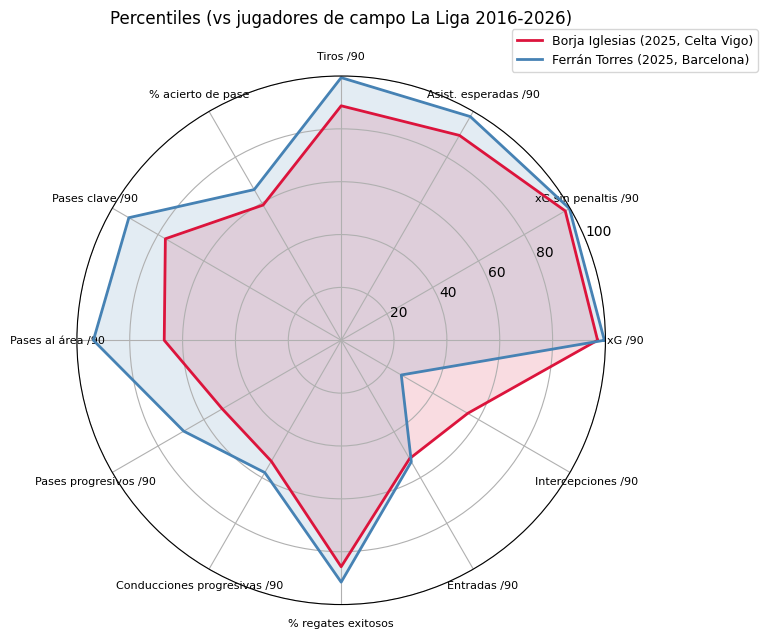

In [77]:
import numpy as np
import matplotlib.pyplot as plt

def radar(nombre_a, anyo_a, nombre_b, anyo_b, features=None):
    """Radar de percentiles comparando dos jugador-temporada."""
    def fila(nombre, anyo):
        m = (field["Player"].str.contains(nombre, case=False, na=False)) & (field["Season_End_Year"] == anyo)
        return field[m].index[0] if m.any() else None
    ia, ib = fila(nombre_a, anyo_a), fila(nombre_b, anyo_b)
    if ia is None or ib is None:
        print("No encuentro a uno de los dos."); return None

    # subconjunto de features legibles para el radar (si no se especifica)
    if features is None:
        features = ["xG_Per", "npxG_Per", "xAG_Per", "Sh_per_90_Standard",
                    "Cmp_percent_Total", "KP_p90", "PPA_p90", "PrgP_Progression_p90",
                    "PrgC_Carries_p90", "Succ_percent_Take", "Tkl_Tackles_p90", "Int_p90"]
    features = [f for f in features if f in FEATURES]

    pct = field[features].rank(pct=True)
    va = pct.loc[ia].values * 100
    vb = pct.loc[ib].values * 100

    ang = np.linspace(0, 2*np.pi, len(features), endpoint=False).tolist()
    va = np.concatenate([va, [va[0]]]); vb = np.concatenate([vb, [vb[0]]])
    ang += ang[:1]

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
    ax.plot(ang, va, linewidth=2, label=field.loc[ia, "label"], color="crimson")
    ax.fill(ang, va, alpha=0.15, color="crimson")
    ax.plot(ang, vb, linewidth=2, label=field.loc[ib, "label"], color="steelblue")
    ax.fill(ang, vb, alpha=0.15, color="steelblue")
    ax.set_xticks(ang[:-1])
    ax.set_xticklabels([bonito(f) for f in features], fontsize=8)
    ax.set_ylim(0, 100)
    ax.set_title("Percentiles (vs jugadores de campo La Liga 2016-2026)", pad=20)
    ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1), fontsize=9)
    plt.tight_layout(); plt.show()

radar("Borja Iglesias", 2025, "Ferrán Torres", 2025)

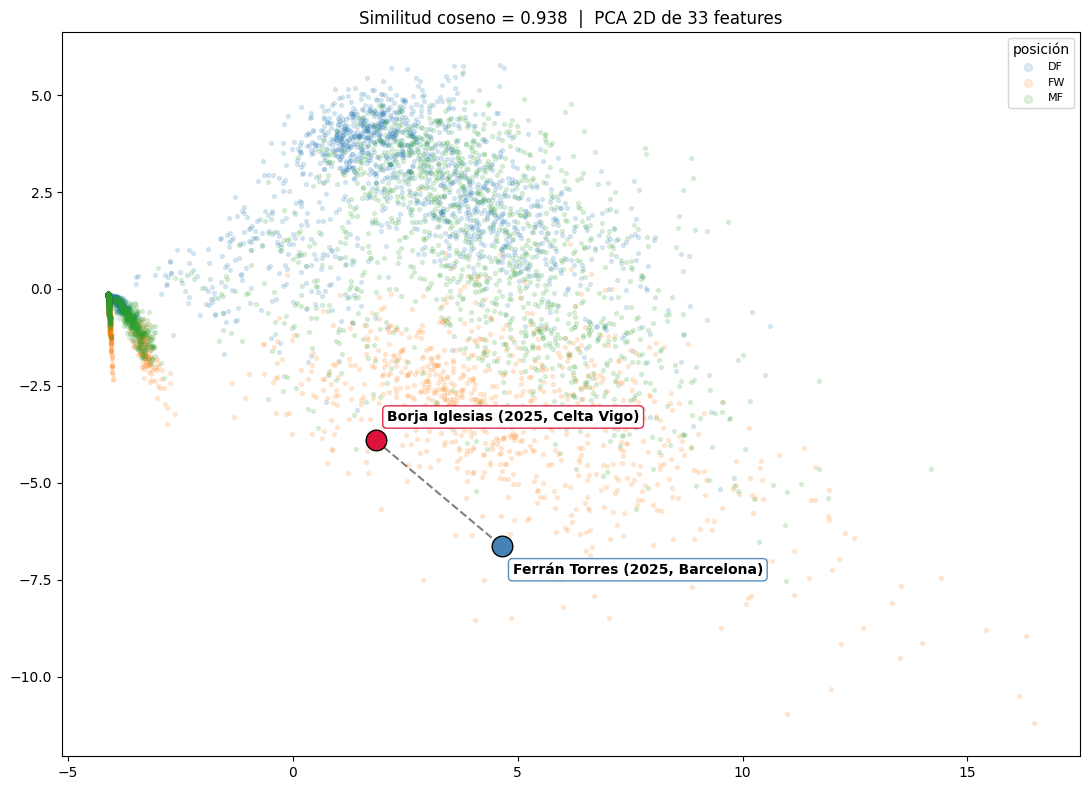

In [64]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

def mapa_dos_jugadores(nombre_a, anyo_a, nombre_b, anyo_b):
    def fila(nombre, anyo):
        m = (field["Player"].str.contains(nombre, case=False, na=False)) & (field["Season_End_Year"] == anyo)
        return field[m].index[0] if m.any() else None
    ia, ib = fila(nombre_a, anyo_a), fila(nombre_b, anyo_b)
    if ia is None or ib is None:
        print("No encuentro a uno de los dos."); return None

    coords = PCA(n_components=2, random_state=0).fit_transform(X)

    fig, ax = plt.subplots(figsize=(11, 8))
    # nube de fondo coloreada por posición (suave)
    for pos, g in field.groupby("pos_group"):
        sel = g.index
        ax.scatter(coords[sel, 0], coords[sel, 1], s=8, alpha=0.15, label=pos)
    # los dos jugadores destacados
    for idx, color, dy in [(ia, "crimson", 14), (ib, "steelblue", -20)]:
        ax.scatter(coords[idx, 0], coords[idx, 1], s=220, color=color,
                   edgecolor="black", zorder=5)
        ax.annotate(field.loc[idx, "label"], (coords[idx, 0], coords[idx, 1]),
                    fontsize=10, fontweight="bold", xytext=(8, dy),
                    textcoords="offset points",
                    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=color, alpha=0.9))
    # línea entre ellos
    ax.plot([coords[ia,0], coords[ib,0]], [coords[ia,1], coords[ib,1]],
            "k--", alpha=0.5, zorder=4)

    # similitud coseno exacta entre ambos
    from sklearn.metrics.pairwise import cosine_similarity
    sim = cosine_similarity(X[ia].reshape(1,-1), X[ib].reshape(1,-1))[0,0]
    ax.set_title(f"Similitud coseno = {sim:.3f}  |  PCA 2D de {len(FEATURES)} features")
    ax.legend(title="posición", markerscale=2, fontsize=8)
    plt.tight_layout(); plt.show()

mapa_dos_jugadores("Borja Iglesias", 2025, "Ferrán Torres", 2025)

## Notas y siguientes pasos
- Si un nombre no aparece, prueba variantes (FBref usa nombres "oficiales").
- Para afinar el parecido por rol, se puede pesar más un bloque (p.ej. creación) o
  entrenar el embedding solo con jugadores de una posición.
- Mejora visual: sustituir PCA por UMAP (`pip install umap-learn`) para clusters más nítidos.
- Este mismo esquema alimenta luego `player_ratings`: el vector estandarizado ES el
  perfil; un rating global sería una combinación ponderada de esas features.